# Everyday wording for patients: evaluation

**Nora MedLink, BS Data Science FYP.** Synthetic reports only.

For every synthetic report the rule-based patient summary is built (no AI), and we measure:

- medical words left without everyday wording (target 0);
- numbers in the summary that are not in the report (target 0);
- reading level (Flesch-Kincaid grade) of the report text and of the summary;
- which medical words patients meet most often (the dictionary's most-used entries).

In [1]:
import os, sys
from pathlib import Path
from collections import Counter

os.environ.setdefault("HF_HUB_OFFLINE", "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "scripts" / "plain_bench")]

import pandas as pd
import matplotlib.pyplot as plt

from services.ai_guard import numbers_not_in_source
from services.icse.entities import extract_entities
from services.patient_summary import build_patient_summary
from services.plain_language import find_terms, unexplained_terms
from services.rule_validation_service import validate_medical_rules
from benchmark_plain import grade, reports

In [2]:
rows, terms = [], Counter()
for name, text in reports():
    summary = build_patient_summary(text, extract_entities(text), validate_medical_rules(text), "Lab")
    found = find_terms(text)
    terms.update(term.plain for _, _, _, term in found)
    rows.append({"report": name, "medical_words": len(found), "unexplained": len(unexplained_terms(summary)),
                 "invented_numbers": len(numbers_not_in_source(summary, text)),
                 "grade_report": grade(text), "grade_summary": grade(summary), "summary_words": len(summary.split())})
frame = pd.DataFrame(rows)
frame.describe().loc[["count", "mean", "min", "max"]]

,medical_words,unexplained,invented_numbers,grade_report,grade_summary,summary_words
count,57.000000,57.0,57.0,57.000000,57.000000,57.000000
mean,9.807018,0.0,0.0,6.040253,5.038738,303.491228
min,4.000000,0.0,0.0,4.639725,3.844808,228.000000
max,27.000000,0.0,0.0,7.781588,6.343604,477.000000


summaries with a medical word left unexplained: 0
summaries with a number not in the report:    0


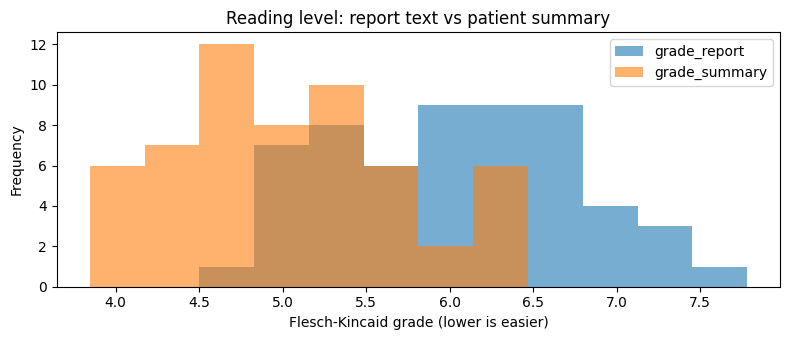

In [3]:
print("summaries with a medical word left unexplained:", int((frame["unexplained"] > 0).sum()))
print("summaries with a number not in the report:   ", int((frame["invented_numbers"] > 0).sum()))
ax = frame[["grade_report", "grade_summary"]].plot.hist(bins=12, alpha=0.6, figsize=(8, 3.5))
ax.set_xlabel("Flesch-Kincaid grade (lower is easier)"); ax.set_title("Reading level: report text vs patient summary")
plt.tight_layout(); plt.show()

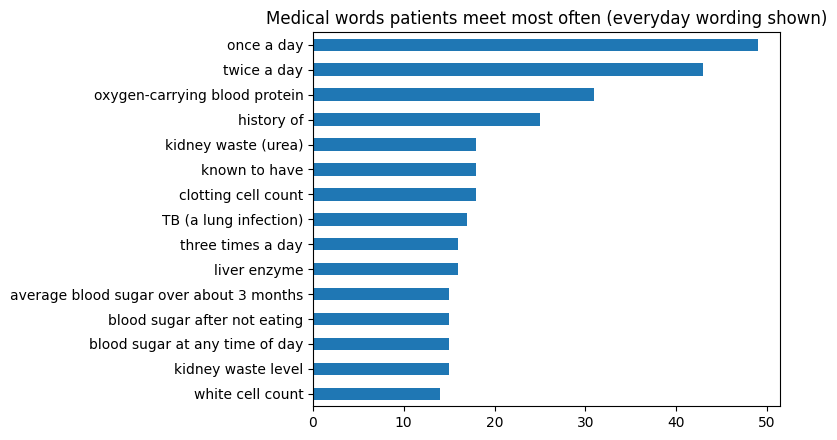

In [4]:
top = pd.Series(terms).sort_values(ascending=False).head(15)
ax = top.sort_values().plot.barh(figsize=(8, 4.5))
ax.set_title("Medical words patients meet most often (everyday wording shown)"); plt.tight_layout(); plt.show()

## Conclusions

- Every summary explains every medical word it uses, and states no number that is not in the report (the same check that rejects an AI summary with an invented number).
- The summary reads at a lower grade than the report text, even though it adds explanations in brackets.
- The dictionary is a demo knowledge base: its wording needs a clinician's review before any real use.